In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import optimizers

# Finding Partial Derivatives with GradientTape

Partial Derivatives are roughly the same when setting a step value of 0.001. Namely 0.2689, 0.6966, and 0.2500

In [5]:
@tf.function
def get_derivative(x, y, z):
    with tf.GradientTape() as tape:
        f = (x/y) + (z**2) + tf.math.sigmoid(x)
    return tape.gradient(f, [x, y, z])

x = tf.Variable(-1.0)
y = tf.Variable(2.0)
z = tf.Variable(2.0)

dw_dx, dw_dy, dw_dz = get_derivative(x, y, z)

print(f"Partial derivative of f w.r.t. x (∂f/∂x): {dw_dx.numpy()}")
print(f"Partial derivative of f w.r.t. y (∂f/∂y): {dw_dy.numpy()}")
print(f"Partial derivative of f w.r.t. z (∂f/∂z): {dw_dz.numpy()}")

Partial derivative of f w.r.t. x (∂f/∂x): 0.6966119408607483
Partial derivative of f w.r.t. y (∂f/∂y): 0.25
Partial derivative of f w.r.t. z (∂f/∂z): 4.0


# Adjusting Geometry of Binary Classifier Point Clouds

## Original 
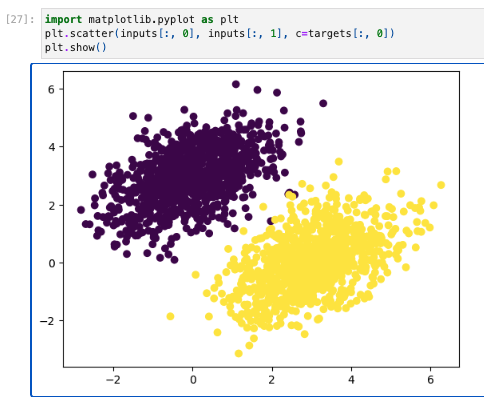

## Making Covariance Matrix Spherical in Nature
### We do this by reflecting along a modifier of the Identity Matrix
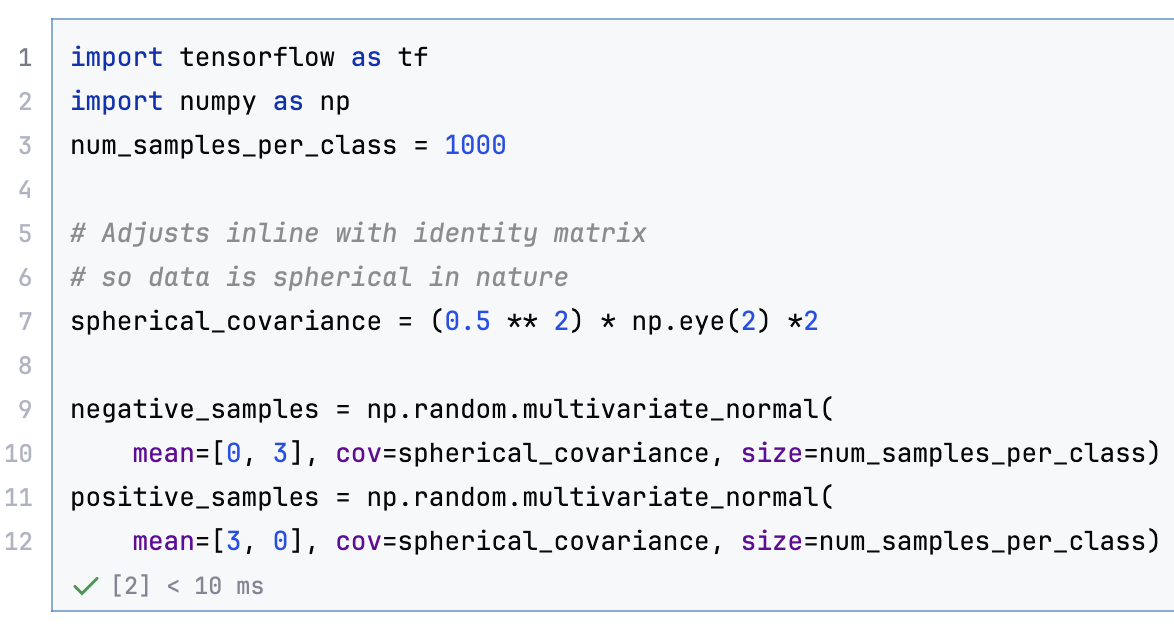

## Adjusting Colors to Green and Red
### Accomplished with ListedColormap
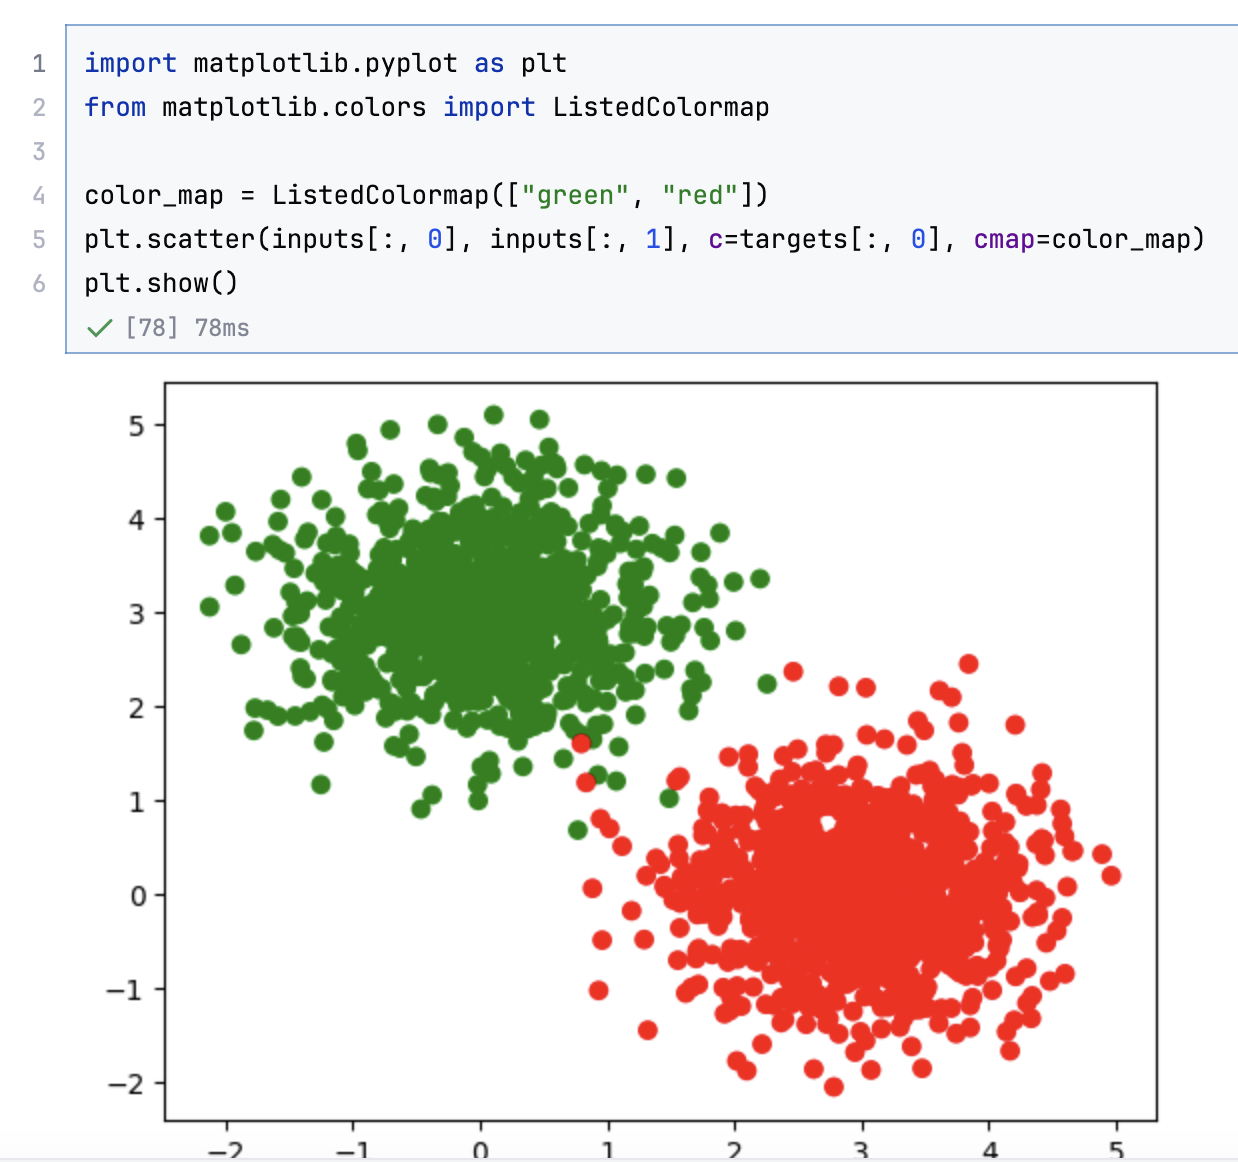

## Changing line to black and dashed
### Accomplished with the k-- parameter
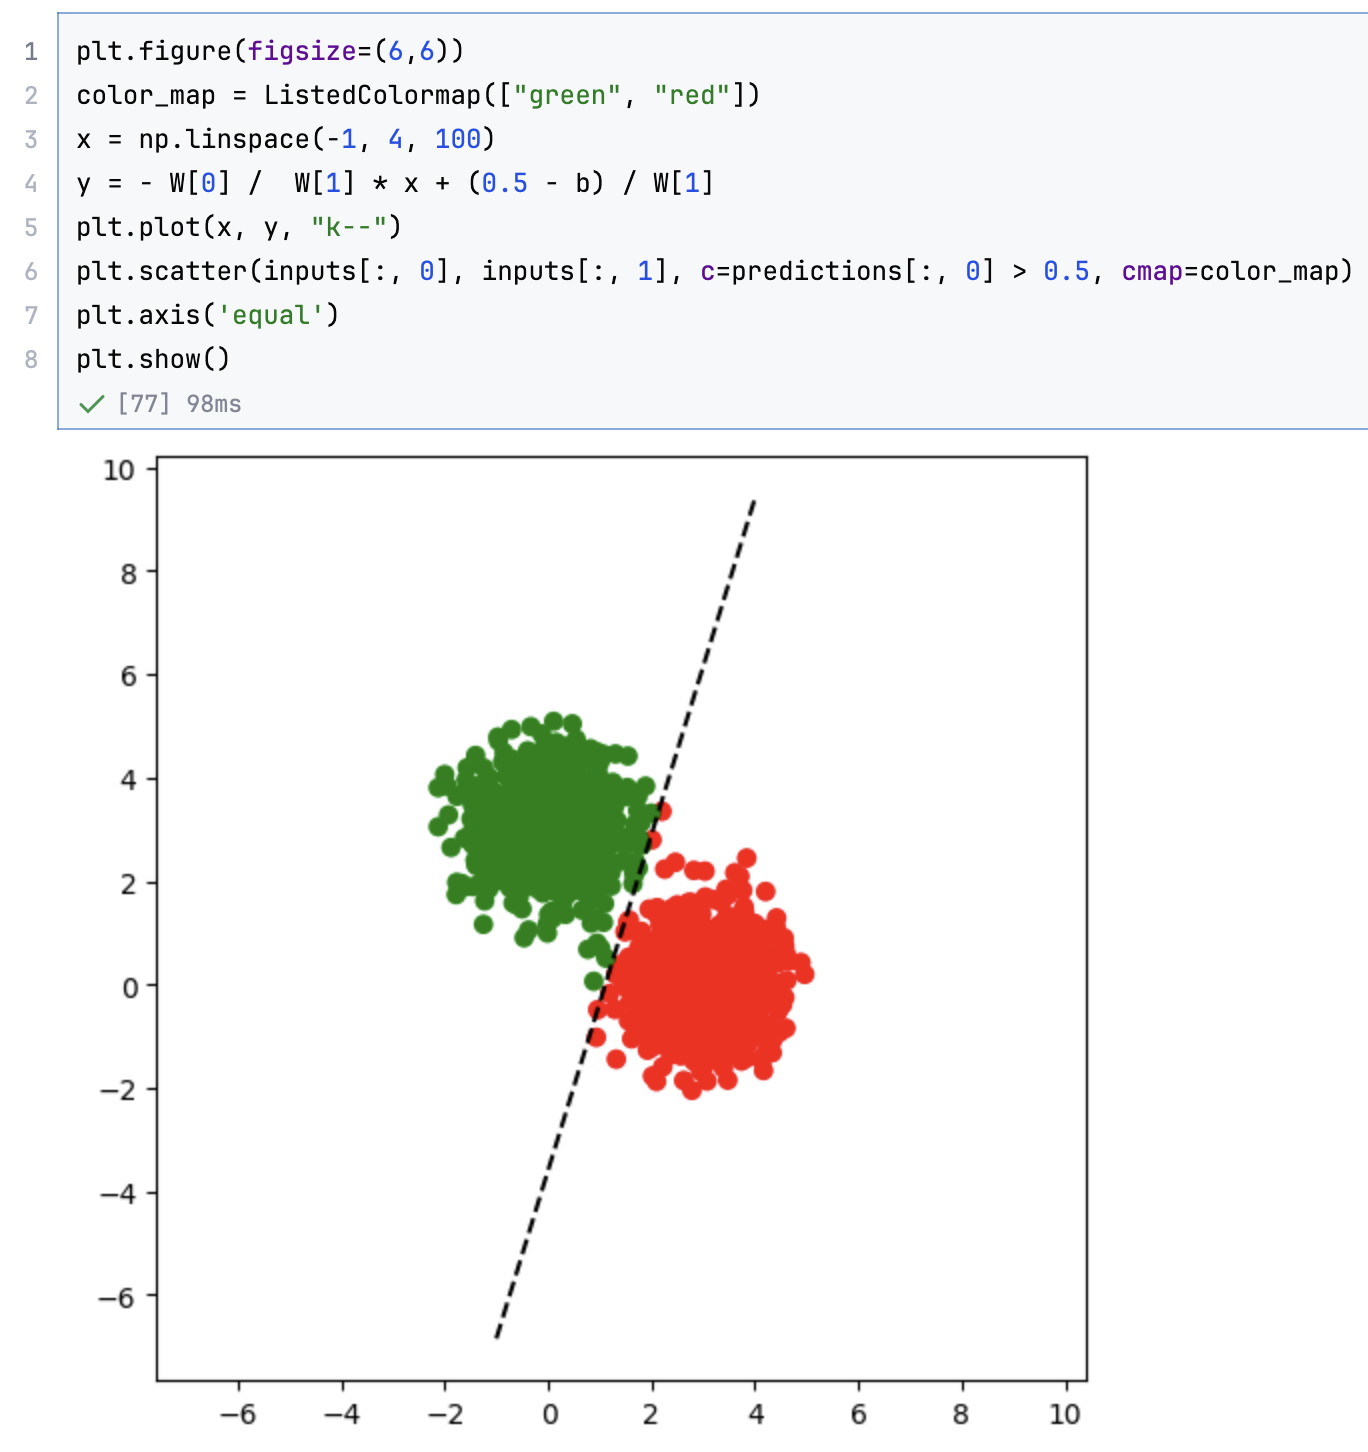

# Gradients of Regression


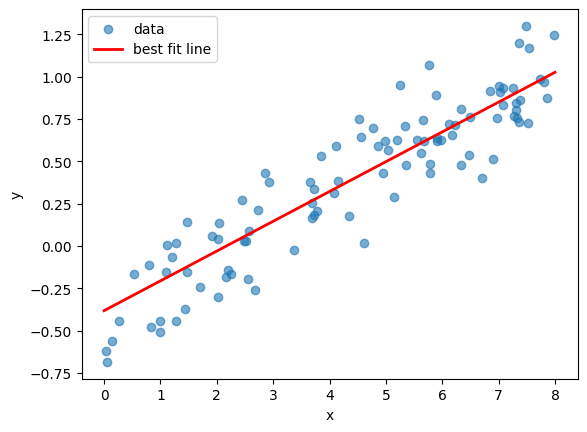

In [6]:
# Builds 100 synthetic data points
synthetic = 100

# Builds a Uniform Distribution
x_np = np.random.uniform(0.0, 8.0, size=(synthetic, 1))

# Defines dependent y as y = 0.2x - 0.5
true_m, true_b = 0.2, -0.5

# Defines Gaussian noise
noise_stdev_range = [0.0, 0.2]
gaussian_noise = np.random.normal(0.0, 0.2, size=(synthetic, 1))

# Applies Gaussian noise to linear equation
y_np = (true_m * x_np) + (true_b + gaussian_noise)

# Builds tensors from x and y
x = tf.convert_to_tensor(x_np, dtype=tf.float32)
y = tf.convert_to_tensor(y_np, dtype=tf.float32)

# Models m and b
model_m = tf.Variable(tf.random.normal([1, 1], stddev=0.1))
model_b = tf.Variable(tf.zeros([1], dtype=tf.float32))

# Plots data
def plot(x_np, y_np, model_m, model_b):
    plt.scatter(x_np, y_np, label = "data", alpha = 0.6)
    x_line = np.linspace(0, 8, 100).reshape(-1, 1)
    y_line = x_line * model_m.numpy() + model_b.numpy()
    plt.plot(x_line, y_line, color = "red", label = "best fit line", linewidth = 2)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()
    plt.show()

# Defines mean-squared-error function
def mean_square_loss(targets, predictions):
    return tf.reduce_mean(tf.square(targets - predictions))

def predict(inputs):
    return tf.matmul(inputs, model_m) + model_b

# Handles application of gradients
def apply_gradients(optimizer, gradients, model_m, model_b):
    optimizer.apply_gradients(zip(gradients, [model_m, model_b]))

def train():
    # Defines a Gradient Descent Optimizer
    learning_rate = 0.005
    optimizer = optimizers.SGD(learning_rate = learning_rate)

    # Repeats epoch for a full training loop
    for epoch_counter in range(1000):
        with tf.GradientTape() as tape:
            # makes predictions from x
            y_hat = predict(x)
            # determines difference between
            # expected and actual values
            loss = mean_square_loss(y, y_hat)
            # occasionally was required to 
            # restart Kernel because loss was NaN
            tf.debugging.check_numerics(loss, "Loss is NaN/Inf")
        # determines gradient between loss function and m & b
        # and then apply gradients to gradienttape
        gradients = tape.gradient(loss, [model_m, model_b])
        apply_gradients(optimizer, gradients, model_m, model_b)
    
    plot(x_np, y_np, model_m, model_b)

train()